# EMQA_L2_qra_week

**A week of QRA intervals in Romania: wide in the evening, narrow at night**

Energy Markets Quantitative Analysis (EMQA), Lecture 2 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L2/EMQA_L2_qra_week/EMQA_L2_qra_week.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# course chart style: transparent background, no grid, legend at the bottom outside the axes
plt.rcParams.update({
    "figure.facecolor": "none", "axes.facecolor": "none", "savefig.transparent": True,
    "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#222222", "axes.labelcolor": "#222222", "xtick.color": "#222222", "ytick.color": "#222222",
    "text.color": "#222222", "font.size": 11, "axes.titlesize": 11.5, "axes.labelsize": 11,
    "legend.fontsize": 10.5, "legend.frameon": False, "lines.linewidth": 1.4, "font.family": "DejaVu Sans"})
PAL = {"RO": "#2a78d6", "DE_LU": "#eb6834", "HU": "#1baf7a", "BG": "#eda100",
       "c5": "#e87ba4", "c6": "#008300", "c7": "#6250d6", "c8": "#e34948"}   # fixed colour per entity


def legend_bottom(fig, handles=None, labels=None, ncol=4, y=0.0):
    """Legend centred under the axes, outside the plotting area."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for hh, ll in zip(*ax.get_legend_handles_labels()):
                if ll not in labels:
                    handles.append(hh)
                    labels.append(ll)
    if handles:
        fig.legend(handles, labels, loc="lower center", ncol=ncol, bbox_to_anchor=(0.5, y),
                   frameon=False, handlelength=2.0, columnspacing=1.2)

## Data and cut-off

In [3]:
TZ = "Europe/Brussels"
PD = pd.read_csv(DATA + "power_da_prices_daily_cet.csv", parse_dates=["date_cet"]).set_index("date_cet")
_hydro = pd.read_csv(DATA + "generation_ro_mw_daily_cet.csv", usecols=["date_cet", "hydro_run_of_river"],
                     parse_dates=["date_cet"]).set_index("date_cet")["hydro_run_of_river"]
# cut-off = last complete month covered by the prices and the Romanian generation data
_raw_last = min(PD["RO"].dropna().index.max(), _hydro.dropna().index.max())
END = pd.Timestamp(((_raw_last + pd.Timedelta(days=1)).to_period("M").to_timestamp() - pd.Timedelta(days=1)).date())
START = pd.Timestamp("2022-01-01")
N_TEST, N_BURN = 365, 182                                  # test year; burn-in (its forecasts only feed QRA, CP, HS)
TEST0 = END - pd.Timedelta(days=N_TEST - 1)
FC0 = TEST0 - pd.Timedelta(days=N_BURN)
FDAYS = pd.date_range(FC0, END, freq="D")                  # burn-in + test days
TDAYS = pd.date_range(TEST0, END, freq="D")                # test days
print("cut-off:", END.date(), "| test year:", TEST0.date(), "to", END.date())

cut-off: 2026-10-31 | test year: 2025-11-01 to 2026-10-31


## Panels of price, load and wind + solar

In [4]:
def day_matrix(s):
    """UTC-indexed hourly series -> CET delivery day x 24 hours (Assignment 1 / epftoolbox DST convention) + DST flag."""
    s = s.copy()
    s.index = pd.to_datetime(s.index, utc=True).tz_convert(TZ)
    df = pd.DataFrame({"v": s.values, "day": s.index.tz_localize(None).normalize(), "h": s.index.hour})
    m = df.groupby(["day", "h"])["v"].mean().unstack("h").reindex(columns=range(24))     # 25-h day: doubled hour averaged
    days = m.index
    nh = ((((days + pd.Timedelta(days=1)).tz_localize(TZ)) - days.tz_localize(TZ)) / pd.Timedelta(hours=1)).astype(int)
    dst = pd.Series(np.asarray(nh != 24), index=days)
    for dd in days[dst.values]:
        if pd.isna(m.loc[dd, 2]):
            m.loc[dd, 2] = 0.5 * (m.loc[dd, 1] + m.loc[dd, 3])                              # 23-h day: h02 = mean(h01, h03)
    m = m.dropna(how="any")
    return m, dst.reindex(m.index)


HP = pd.read_csv(DATA + "power_da_prices_hourly_utc.csv", index_col=0, usecols=["timestamp_utc", "RO"])
PM, DST = day_matrix(HP["RO"].dropna())
CAL = pd.date_range(START, END, freq="D")
PM, DST = PM.reindex(CAL), DST.reindex(CAL)
GH = pd.read_csv(DATA + "generation_ro_mw_hourly_utc.csv", index_col=0, usecols=["timestamp_utc", "load", "wind_onshore", "solar"])
LM, _ = day_matrix(GH["load"].dropna())
RM, _ = day_matrix((GH["wind_onshore"] + GH["solar"]).dropna())
LM, RM = LM.reindex(CAL), RM.reindex(CAL)
assert not PM.isna().any().any() and not LM.isna().any().any() and not RM.isna().any().any(), "panel has gaps"
L_, R_ = LM.values.astype(float), RM.values.astype(float)
P_ = PM.values.astype(float)
DOW = CAL.dayofweek.values
IDX = {t: i for i, t in enumerate(CAL)}
TI_ROWS = np.array([IDX[t] for t in TDAYS])              # panel rows of the test days
A = P_[TI_ROWS]                                          # actual prices of the test year, days x 24
# naive benchmark: same hour of d-7 on Monday, Saturday, Sunday, of d-1 otherwise
NAIVE = np.array([P_[i - 7] if DOW[i] in (0, 5, 6) else P_[i - 1] for i in TI_ROWS])
print("panel:", CAL[0].date(), "to", CAL[-1].date(), len(CAL), "days x 24 hours")

panel: 2022-01-01 to 2026-10-31 1765 days x 24 hours


## Expert ARX functions (used by the recomputation)

The expert ARX model (one OLS regression per hour, Assignment 1 specification) is cheap and is recomputed here for the six calibration windows 56, 84, 112, 714, 721 and 728 days; AW-ARX is their average.

In [5]:
from scipy import stats


def shift_rows(A, k):
    out = np.full_like(A, np.nan)
    out[k:] = A[:-k]
    return out


def mad_scale(x):
    x = np.asarray(x, float).ravel()
    m = np.median(x)
    s = stats.median_abs_deviation(x, scale="normal")
    return m, (s if s > 0 else 1.0)


def arx_day(Pa, La, Ra, Fa, i, T, kind="asinh"):
    """Expert ARX (Assignment 1, Ziel & Weron 2018 style), one regression per hour; target day = row i.
    Calibration targets rows i-T..i-1; VST median/MAD from price rows i-T-7..i-1; L,R z-scores from rows i-T-7..i-2."""
    P1, P2, P7 = shift_rows(Pa, 1), shift_rows(Pa, 2), shift_rows(Pa, 7)
    lo = i - T
    if kind == "raw":
        m, s = 0.0, 1.0
        f = lambda x: x  # noqa: E731
        finv = f
    else:
        m, s = mad_scale(Pa[lo - 7:i])
        f = lambda x: np.arcsinh((x - m) / s)  # noqa: E731
        finv = lambda y: m + s * np.sinh(y)  # noqa: E731
    rows = slice(lo, i + 1)
    Y, Y1, Y2, Y7 = f(Pa[rows]), f(P1[rows]), f(P2[rows]), f(P7[rows])
    mu_l, sd_l = np.mean(La[lo - 7:i - 1]), np.std(La[lo - 7:i - 1])
    mu_r, sd_r = np.mean(Ra[lo - 7:i - 1]), np.std(Ra[lo - 7:i - 1])
    Lz = (shift_rows(La, 2)[rows] - mu_l) / sd_l
    Rz = (shift_rows(Ra, 2)[rows] - mu_r) / sd_r
    dw = DOW[rows]
    dmy = np.column_stack([dw == 0, dw == 5, dw == 6]).astype(float)
    extra = None
    if kind == "fund":
        Fr = Fa[rows]
        extra = (Fr - np.nanmean(Fr[:-1], axis=0)) / np.nanstd(Fr[:-1], axis=0)
    n = T + 1
    out, coefs = np.zeros(24), np.zeros((24, 12))
    if kind == "single":                                          # one pooled regression, common slopes, hour intercepts
        Xs, ys = [], []
        for h in range(24):
            hd = np.zeros((n, 24))
            hd[:, h] = 1
            Xs.append(np.column_stack([hd, Y1[:, h], Y2[:, h], Y7[:, h], Y1[:, 23], Y1.min(1), Y1.max(1), Lz[:, h], Rz[:, h], dmy]))
            ys.append(Y[:, h])
        Xs, ys = np.stack(Xs, 1), np.stack(ys, 1)                 # n x 24 x p
        Xc, yc = Xs[:-1].reshape(-1, Xs.shape[2]), ys[:-1].ravel()
        b = np.linalg.lstsq(Xc, yc, rcond=None)[0]
        return finv(Xs[-1] @ b), None
    for h in range(24):
        cols = [np.ones(n), Y1[:, h], Y2[:, h], Y7[:, h], Y1[:, 23], Y1.min(1), Y1.max(1)]
        if kind != "noexog":
            cols += [Lz[:, h], Rz[:, h]]
        cols += [dmy[:, 0], dmy[:, 1], dmy[:, 2]]
        X = np.column_stack(cols)
        if h == 23:
            X = np.delete(X, 4, axis=1)                           # Y_{d-1,23} appears twice for h = 23
        if extra is not None:
            X = np.column_stack([X, extra])
        b = np.linalg.lstsq(X[:-1], Y[:-1, h], rcond=None)[0]
        out[h] = X[-1] @ b
        if kind == "asinh" and h != 23 and X.shape[1] == 12:
            coefs[h] = b
    return finv(out), coefs


ARX_W = (56, 84, 112, 714, 721, 728)

## Quantile regression averaging (QRA)

For each hour, 99 quantile regressions of the actual price on the AW-ARX and AW-LEAR forecasts of the previous 182 days (burn-in + test), refitted every week; the quantiles are then sorted (no crossing). This needs the LEAR forecasts of 547 days and 24 x 99 quantile regressions per week, so the quantiles computed by `lectures/L2/analysis_L2.py` are loaded from the file saved next to this notebook (the week shown and the median of every test hour). `RUN_ALL = True` recomputes everything.

In [6]:
# the week of the chart: last full Monday-Sunday week of the test year without a clock change
# Mondays whose week ends inside the test year
mons = [t for t in TDAYS if t.dayofweek == 0 and t + pd.Timedelta(days=6) <= END]
TPOS = {t: k for k, t in enumerate(TDAYS)}                # row of a test day
PW = max(t for t in mons if not DST.loc[t:t + pd.Timedelta(days=6)].any())
pw = slice(TPOS[PW], TPOS[PW] + 7)
print("week:", PW.date(), "to", (PW + pd.Timedelta(days=6)).date())

week: 2026-10-12 to 2026-10-18


In [7]:
RUN_ALL = False   # True: recompute the forecasts from the data (LEAR roughly 70 min, QRA roughly 10 min on one core; joblib uses all cores)

QL = REPO + "Quantlets/L2/EMQA_L2_qra_week/"          # saved results of this Quantlet


def load_npz(path):
    if path.startswith("http"):
        import io
        import urllib.request
        return np.load(io.BytesIO(urllib.request.urlopen(path).read()))
    return np.load(path)


def load_csv(name, days):
    S = pd.read_csv(QL + name, parse_dates=["date"], float_precision="round_trip")
    assert (pd.DatetimeIndex(S["date"].drop_duplicates()) == days).all()
    return S


F_ROWS = np.array([IDX[t] for t in FDAYS])              # panel rows of the burn-in + test days
PLAGS, XLAGS = (1, 2, 3, 7), (2, 3, 7)                   # price lags; lags of load and wind+solar (days)
LEAR_W = (364, 546, 728)


def lear_design(Pa, La, Ra, lo, i):
    """LEAR regressors (Assignment 1: 247 columns) for rows lo..i, with transforms fitted on rows available at gate closure."""
    m, s = mad_scale(Pa[lo - 7:i])
    mL, sL = mad_scale(La[lo - 7:i - 1])
    mR, sR = mad_scale(Ra[lo - 7:i - 1])
    rows = slice(lo, i + 1)
    blocks = [np.arcsinh((shift_rows(Pa, k)[rows] - m) / s) for k in PLAGS]
    blocks += [np.arcsinh((shift_rows(La, k)[rows] - mL) / sL) for k in XLAGS]
    blocks += [np.arcsinh((shift_rows(Ra, k)[rows] - mR) / sR) for k in XLAGS]
    blocks.append(np.eye(7)[DOW[rows]])
    X = np.column_stack(blocks)
    Y = np.arcsinh((Pa[rows] - m) / s)
    return X, Y, m, s


def lear_day(Pa, La, Ra, i, T):
    from sklearn.linear_model import LassoLarsIC
    lo = i - T
    X, Y, m, s = lear_design(Pa, La, Ra, lo, i)
    mu, sd = X[:-1].mean(0), X[:-1].std(0)
    sd[sd == 0] = 1.0
    Xs = (X - mu) / sd
    out, nz = np.zeros(24), np.zeros((24, X.shape[1]), bool)
    for h in range(24):
        mdl = LassoLarsIC(criterion="aic", max_iter=2000).fit(Xs[:-1], Y[:-1, h])
        out[h] = mdl.predict(Xs[-1:])[0]
        nz[h] = mdl.coef_ != 0
    return m + s * np.sinh(out), nz


import statsmodels.api as sm
from statsmodels.regression.quantile_regression import QuantReg
TAUS = np.arange(1, 100) / 100                           # 99 quantile levels
W_QRA = 182                                              # QRA calibration: the previous 182 forecast days
WEEK0 = list(range(N_BURN, len(FDAYS), 7))               # QRA refitted weekly


def qra_hour(h):
    import warnings as _w
    _w.filterwarnings("ignore")                                 # iteration-limit warnings at the extreme quantiles
    out = np.full((len(FDAYS), len(TAUS)), np.nan)
    for w in WEEK0:
        tr = np.arange(w - W_QRA, w)
        assert tr.max() < w and tr.min() >= 0                     # past forecasts only
        X = sm.add_constant(np.column_stack([FA[tr, h], FL_[tr, h]]))
        y = ACT_F[tr, h]
        te = np.arange(w, min(w + 7, len(FDAYS)))
        Xt = sm.add_constant(np.column_stack([FA[te, h], FL_[te, h]]), has_constant="add")
        for j, tau in enumerate(TAUS):
            b = QuantReg(y, X).fit(q=tau, max_iter=5000).params
            out[te, j] = Xt @ b
    return out


if RUN_ALL:
    from joblib import Parallel, delayed
    _r = Parallel(n_jobs=-1)(delayed(lear_day)(P_, L_, R_, i, T) for T in LEAR_W for i in F_ROWS)
    _n = len(F_ROWS)
    LEAR = {T: np.array([r[0] for r in _r[k * _n:(k + 1) * _n]]) for k, T in enumerate(LEAR_W)}
    # QRA regresses the actual price on the AW-ARX and AW-LEAR forecasts of the previous 182 days
    FA = np.mean([np.array([arx_day(P_, L_, R_, None, i, T)[0] for i in F_ROWS]) for T in ARX_W], 0)
    FL_ = np.mean([LEAR[T] for T in LEAR_W], 0)
    ACT_F = P_[F_ROWS]
    QRA = np.stack(Parallel(n_jobs=-1)(delayed(qra_hour)(h) for h in range(24)), 1)
    QRA = np.sort(QRA[N_BURN:], axis=2)                     # test year; rearranged: no quantile crossing
else:
    Z = load_npz(QL + "qra_week.npz")
    assert str(Z["week_start"]) == str(PW.date())
    QW, QMED = Z["week"], Z["median"]                          # week x 24 x 99 quantiles; test days x 24
if RUN_ALL:
    QW, QMED = QRA[pw], QRA[:, :, 49]
print("QRA median, MAE on the test year: %.2f EUR/MWh" % np.mean(np.abs(A - QMED)))

QRA median, MAE on the test year: 22.14 EUR/MWh


## The chart

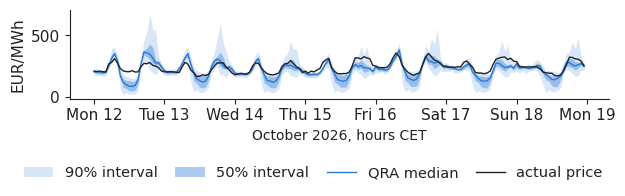

In [8]:
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

DAYN = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
xt = pd.date_range(PW, periods=168, freq="h")
qw = QW.reshape(168, 99)
fig, ax = plt.subplots(figsize=(6.4, 2.0))
ax.fill_between(xt, qw[:, 4], qw[:, 94], color=PAL["RO"], alpha=0.18, lw=0, label="90% interval")
ax.fill_between(xt, qw[:, 24], qw[:, 74], color=PAL["RO"], alpha=0.38, lw=0, label="50% interval")
ax.plot(xt, qw[:, 49], color=PAL["RO"], lw=1.0, label="QRA median")
ax.plot(xt, A[pw].ravel(), color="#222222", lw=1.0, label="actual price")
ax.set_ylabel("EUR/MWh")
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{DAYN[mdates.num2date(v).weekday()]} {mdates.num2date(v).day}"))
ax.set_xlabel(f"{PW:%B %Y}" + (f" - {PW + pd.Timedelta(days=6):%B %Y}" if (PW + pd.Timedelta(days=6)).month != PW.month else "") + ", hours CET", fontsize=10)
legend_bottom(fig, ncol=4)
fig.tight_layout(rect=(0, 0.17, 1, 1))
plt.savefig('qra_week.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()

In [9]:
print("Numbers on the slide")
print(f'  first day of the week: {str(PW.date()):s}')
print(f'  last day of the week: {str((PW + pd.Timedelta(days=6)).date()):s}')
print(f'  MAE of the QRA median, test year: {np.mean(np.abs(A - QMED)):.2f}')

Numbers on the slide
  first day of the week: 2026-10-12
  last day of the week: 2026-10-18
  MAE of the QRA median, test year: 22.14
